In [7]:
import os
import requests
import zipfile
import warnings
import tarfile
import pandas as pd
import geopandas as gpd
from tqdm import tqdm
from io import StringIO, BytesIO
from sqlalchemy import create_engine

import matplotlib.pyplot as plt

from pathlib import Path
from src.baer import BAERData

from src.landsat_get import Landsat

In [101]:
meta_data = []
for year in range(2012, 2022):
    baer = BAERData(save_data_path='data/baer_data/', years=[year], pattern='.tif')
    meta_data.append(baer.metadata_request)
    
baer_metadata = pd.concat(meta_data)

BAER - Getting metadata [[2021]]: 100%|█████████████████████████████████████████████████████████████████████████████████████| 11/11 [00:00<00:00, 784.32it/s]


In [109]:
baer_metadata['fire_id'] = baer_metadata.fire_id.astype(str).str.upper()
baer_metadata_merge = baer_metadata.merge(mtbs, left_on='fire_id', right_on='Event_ID', how='left')

In [135]:
mtbs_totals = (mtbs
               .groupby([mtbs.Ig_Date.dt.year, mtbs.Incid_Type])
               .Event_ID
               .count()
               .reset_index()
              )
baer_totals = (baer_metadata_merge
               .groupby([baer_metadata_merge.Ig_Date.dt.year, baer_metadata_merge.Incid_Type])
               .id
               .count()
               .reset_index()
               .merge(mtbs_totals, on=["Ig_Date", "Incid_Type"], how='left')
              )
baer_totals['ratio'] = baer_totals.id/baer_totals.Event_ID
baer_totals.set_index("Ig_Date", inplace=True)

In [134]:
baer_totals

,Ig_Date,Incid_Type,id,Event_ID,ratio
0,2012.0,Wildfire,83,572,0.145105
1,2013.0,Wildfire,62,301,0.205980
2,2014.0,Wildfire,54,267,0.202247
3,2015.0,Wildfire,65,537,0.121043
4,2016.0,Prescribed Fire,1,447,0.002237
5,2016.0,Wildfire,72,516,0.139535
6,2017.0,Wildfire,139,645,0.215504
7,2018.0,Wildfire,97,523,0.185468
8,2019.0,Wildfire,58,380,0.152632
9,2020.0,Wildfire,104,469,0.221748


In [2]:
import rasterio
import matplotlib.pyplot as plt

{'driver': 'GTiff', 'dtype': 'int16', 'nodata': None, 'width': 496, 'height': 462, 'count': 1, 'crs': CRS.from_epsg(32611), 'transform': Affine(30.0, 0.0, 420185.0,
       0.0, -30.0, 3798202.0)}


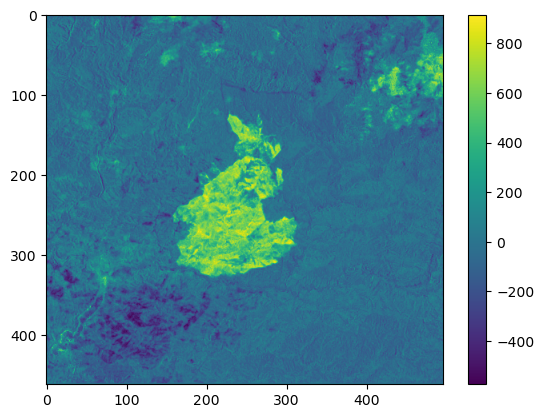

In [199]:
from rasterio.plot import show

with rasterio.open('data/baer_data/2012/ca3423811772220120902_20110913_20120908_dnbr.tif') as src:
    print(src.meta)
    data = src.read(1)
    plt.imshow(data)
    plt.colorbar()

In [4]:
from shapely.geometry import Polygon

def create_polygon(north_lat, south_lat, west_lon, east_lon):
    """ Create polygon from corner coordinates

    Take a set of point coordinates and transform into a shapely Polygon object.
    This function can be passed to a pd.apply() function.

    Args:
        - north_lat, south_lat, west_lon, east_lon: point coordinates of
          bounding box.

    Returns:
        shapely.geom.Polygon
    """

    # Create corner coordinates
    coords = []
    for lon in [west_lon, east_lon]:
        for lat in [north_lat, south_lat]:
            c = tuple([lon, lat])
            coords.append(c)

    return Polygon([coords[1], coords[0], coords[2], coords[3]])



In [46]:
client = create_engine("postgresql://topcat@localhost:5432/landsat")

In [15]:
mtbs = gpd.read_file('data/mtbs_perims_DD/mtbs_perims_DD.shp', parse_dates=["Ig_Date"])
mtbs = mtbs.to_crs("EPSG:4326")
mtbs['Ig_Date'] = pd.to_datetime(mtbs['Ig_Date'])

In [9]:
us_coords = {
        'north_lat': 49.3457868, 
        'west_lon': -124.7844079,
        'east_lon': -66.9513812,
        'south_lat': 24.7433195,
        }
us_bbox = create_polygon(**us_coords)

landsat = pd.read_csv('metadata.csv.gz', iterator=True, chunksize=10000)

l8_lst = []
for chunk in landsat: 
    chunk = chunk[(chunk.COLLECTION_CATEGORY == 'T1')
                  & (chunk.CLOUD_COVER < 30)
                 ]
    # Create geometry and geopandas
    chunk["geometry"] = chunk.apply(
        lambda x: create_polygon(
            x["NORTH_LAT"], x["SOUTH_LAT"], x["WEST_LON"], x["EAST_LON"]
        ),
        axis=1,
    )
    l8_lst.append(chunk)
l8 = pd.concat(l8_lst)

In [11]:
subset_complete = gpd.GeoDataFrame(
    l8, geometry=l8.geometry, crs="EPSG:4326"
)

subset_complete['DATE_ACQUIRED'] = pd.to_datetime(subset_complete.DATE_ACQUIRED)
conus_landsat = subset_complete[subset_complete.geometry.intersects(us_bbox)]


In [41]:
time_range = pd.date_range(mtbs[mtbs.Incid_Name == "AUGUST COMPLEX"].iloc[0].Ig_Date - pd.Timedelta(days=20),
              mtbs[mtbs.Incid_Name == "AUGUST COMPLEX"].iloc[0].Ig_Date)
time_range

DatetimeIndex(['2020-07-28', '2020-07-29', '2020-07-30', '2020-07-31',
               '2020-08-01', '2020-08-02', '2020-08-03', '2020-08-04',
               '2020-08-05', '2020-08-06', '2020-08-07', '2020-08-08',
               '2020-08-09', '2020-08-10', '2020-08-11', '2020-08-12',
               '2020-08-13', '2020-08-14', '2020-08-15', '2020-08-16',
               '2020-08-17'],
              dtype='datetime64[ns]', freq='D')

In [64]:
query = """
with fire_landsat_join as (select f."Event_ID"      as mtbs_id,
                                  f."Incid_Name"    as fire_name,
                                  f."Ig_Date"       as ignition_date,
                                  l."DATE_ACQUIRED" as date,
                                  f."Incid_Type"    as fire_type,
                                  l."SCENE_ID"      as scene_id,
                                  l."SPACECRAFT_ID" as spacecraft,
                                  l."CLOUD_COVER"   as cloud_cover,
                                  l."BASE_URL" as bucket_url,
                                  (f."Ig_Date" - l."DATE_ACQUIRED") as time_delta,
                                  min((f."Ig_Date" - l."DATE_ACQUIRED")) over (partition by f."Event_ID") as min_time_delta,
                                  l.geometry
                           from mtbs.mtbs as f
                                    left join landsat.filtered_landsat_scenes as l
                                              on st_within(f.geometry, l.geometry)
                                              and l."DATE_ACQUIRED" between f."Ig_Date" - INTERVAL '10 day' and f."Ig_Date"

                           where f."Incid_Type" in ('Wildfire', 'Unknown'))
select
    fire_type,
    spacecraft,
    extract('year' from ignition_date) as year,
    count(*) as number_fires
from fire_landsat_join
where scene_id is null
group by fire_type, extract('year' from ignition_date), spacecraft;
"""
test_db = pd.read_sql(query, con=client)

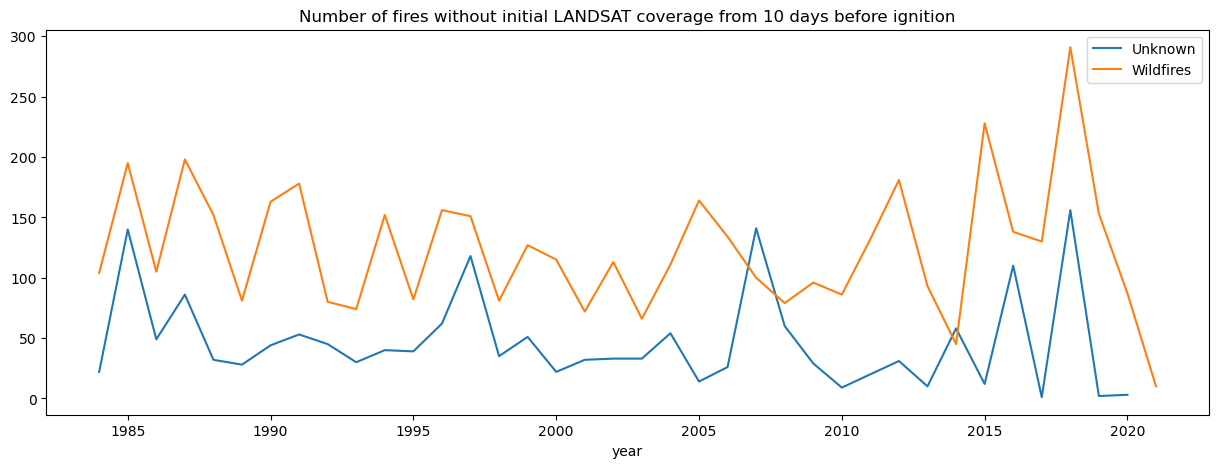

In [84]:
fig, ax = plt.subplots(figsize=(15, 5))
test_db[test_db.fire_type == 'Unknown'].set_index('year').number_fires.plot(ax=ax, label='Unknown')
test_db[test_db.fire_type == 'Wildfire'].set_index('year').number_fires.plot(ax=ax, label='Wildfires')
plt.title('Number of fires without initial LANDSAT coverage from 10 days before ignition')
ax.legend()

In [85]:
query = """
with fire_landsat_join as (select f."Event_ID"      as fire_id,
                                  f."Incid_Name"    as fire_name,
                                  f."Ig_Date"       as ignition_date,
                                  l."DATE_ACQUIRED" as date,
                                  extract('year' from "Ig_Date") as year,
                                  f."Incid_Type"    as fire_type,
                                  l."SCENE_ID"      as scene_id,
                                  l."SPACECRAFT_ID" as spacecraft,
                                  l."CLOUD_COVER"   as cloud_cover,
                                  l."BASE_URL" as bucket_url,
                                  (f."Ig_Date" - l."DATE_ACQUIRED") as time_delta,
                                  min((f."Ig_Date" - l."DATE_ACQUIRED")) over (partition by f."Event_ID") as min_time_delta,
                                  l.geometry
                           from mtbs.mtbs as f
                                    left join landsat.filtered_landsat_scenes as l
                                              on st_within(f.geometry, l.geometry)
                                              and l."DATE_ACQUIRED" between f."Ig_Date" - INTERVAL '10 day' and f."Ig_Date"

                           where f."Incid_Type" in ('Wildfire', 'Unknown')),
totals as (
    select
        "Incid_Type" as fire_type,
        extract(year from "Ig_Date") as year,
        count(*) as total_fires_year
        from mtbs.mtbs
        group by "Incid_Type", extract('year' from "Ig_Date")
)
select
    fire_type,
    year,
    count(distinct fire_id) as number_fires_with_image,
    total_fires_year as total_year_type,
    count(distinct fire_id) / total_fires_year::float as ratio
from (
        select l.*, t.total_fires_year
            from fire_landsat_join l
            left join totals t
         on l.fire_type = t.fire_type and l.year = t.year
         ) db
where scene_id is not null
group by fire_type, year, total_fires_year;
"""
test_db = pd.read_sql(query, con=client)

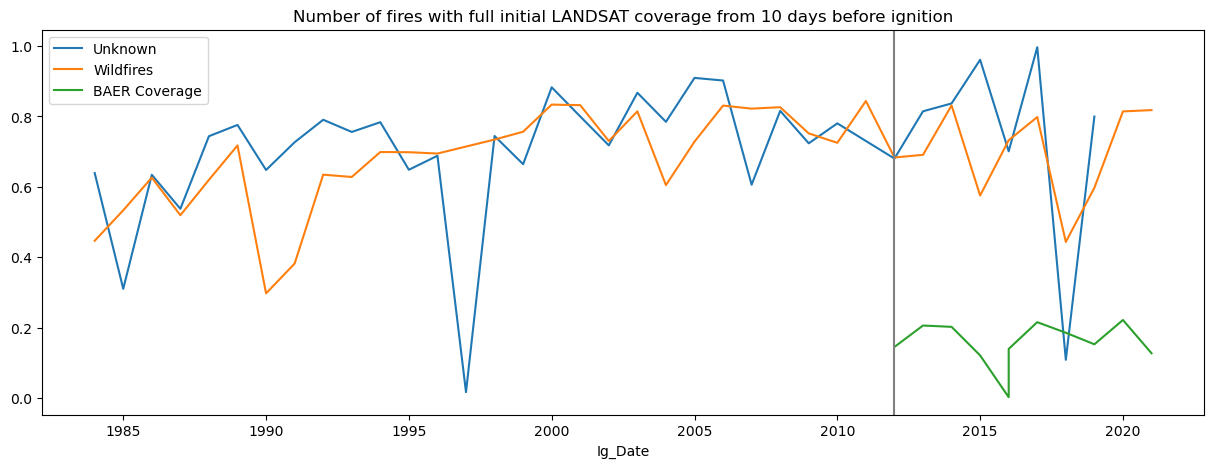

In [138]:
fig, ax = plt.subplots(figsize=(15, 5))
test_db[test_db.fire_type == 'Unknown'].set_index('year').ratio.plot(ax=ax, label='Unknown')
test_db[test_db.fire_type == 'Wildfire'].set_index('year').ratio.plot(ax=ax, label='Wildfires')
baer_totals.ratio.plot(ax=ax, label="BAER Coverage")
plt.axvline(x = 2012, color = 'gray')
plt.title('Percentage of fires with full initial LANDSAT coverage from 10 days before ignition')
ax.legend()

In [143]:
query = """
with fire_landsat_join as (select f."Event_ID"      as fire_id,
                                  f."Incid_Name"    as fire_name,
                                  f."Ig_Date"       as ignition_date,
                                  l."DATE_ACQUIRED" as date,
                                  extract('year' from "Ig_Date") as year,
                                  f."Incid_Type"    as fire_type,
                                  l."SCENE_ID"      as scene_id,
                                  l."SPACECRAFT_ID" as spacecraft,
                                  l."CLOUD_COVER"   as cloud_cover,
                                  l."BASE_URL" as bucket_url,
                                  (f."Ig_Date" - l."DATE_ACQUIRED") as time_delta,
                                  min((f."Ig_Date" - l."DATE_ACQUIRED")) over (partition by f."Event_ID") as min_time_delta,
                                  l.geometry as geom
                           from mtbs.mtbs as f
                                    left join landsat.filtered_landsat_scenes as l
                                              on st_within(f.geometry, l.geometry)
                                              and l."DATE_ACQUIRED" between f."Ig_Date" - INTERVAL '10 day' and f."Ig_Date"

                           where f."Incid_Type" in ('Wildfire', 'Unknown')
                           )
                           select * from fire_landsat_join
"""
test_db = gpd.read_postgis(query, con=client)

In [146]:
test_db[test_db.fire_id == 'OK3669309683920150330']

,fire_id,fire_name,ignition_date,date,year,fire_type,scene_id,spacecraft,cloud_cover,bucket_url,time_delta,min_time_delta,geom
27478,OK3669309683920150330,UNNAMED,2015-03-30,2015-03-30,2015.0,Unknown,LC80270342015089LGN01,LANDSAT_8,0.02,gs://gcp-public-data-landsat/LC08/01/027/034/L...,0 days,0 days,"POLYGON ((-97.25086 36.35362, -97.25086 38.575..."
27479,OK3669309683920150330,UNNAMED,2015-03-30,2015-03-30,2015.0,Unknown,LC80270352015089LGN01,LANDSAT_8,0.02,gs://gcp-public-data-landsat/LC08/01/027/035/L...,0 days,0 days,"POLYGON ((-97.55538 34.96310, -97.55538 37.100..."


In [150]:
query = """
with fire_landsat_join as (select f."Event_ID"      as fire_id,
                                  f."Incid_Name"    as fire_name,
                                  f."Ig_Date"       as ignition_date,
                                  l."DATE_ACQUIRED" as date,
                                  extract('year' from "Ig_Date") as year,
                                  f."Incid_Type"    as fire_type,
                                  l."SCENE_ID"      as scene_id,
                                  l."SPACECRAFT_ID" as spacecraft,
                                  l."CLOUD_COVER"   as cloud_cover,
                                  l."BASE_URL" as bucket_url,
                                  (f."Ig_Date" - l."DATE_ACQUIRED") as time_delta,
                                  min((f."Ig_Date" - l."DATE_ACQUIRED")) over (partition by f."Event_ID") as min_time_delta,
                                  min(l."CLOUD_COVER") over(partition by f."Event_ID") as min_cloud_cover,
                                  max(split_part(l."SPACECRAFT_ID", '_', 2)) over(partition by f."Event_ID") as recent_landsat,
                                  l.geometry as geom_area_image,
                                  f.geometry as polygon_fire
                           from mtbs.mtbs as f
                                    left join landsat.filtered_landsat_scenes as l
                                              on st_within(f.geometry, l.geometry)
                                              and l."DATE_ACQUIRED" between f."Ig_Date" - INTERVAL '10 day' and f."Ig_Date"

                           where f."Incid_Type" in ('Wildfire', 'Unknown')
                           )
select fire_id,
       fire_name,
       ignition_date,
       array_agg(scene_id) as scenes,
       array_agg(bucket_url) as scenes_buckets,
       array_agg(date) as scenes_dates,
       array_agg(spacecraft) as scenes_spacecraft,
       sum(st_area(st_transform(polygon_fire, 3847)))::float  / 1000000 as area_fire,
       count(distinct scene_id) as images_fire
from fire_landsat_join
where scene_id is not null
  and time_delta = min_time_delta
  and cloud_cover = min_cloud_cover
group by fire_id, fire_name,  ignition_date;
"""

test_db = pd.read_sql(query, con=client)

In [156]:
test_db

,fire_id,fire_name,ignition_date,scenes,scenes_buckets,scenes_dates,scenes_spacecraft,area_fire,images_fire
0,AL3034808781020141129,MAGNOLIA SPRINGS,2014-11-29,[LE70200392014333EDC03],[gs://gcp-public-data-landsat/LE07/01/020/039/...,[2014-11-29 00:00:00],[LANDSAT_7],10.885878,1
1,AL3038308812219980404,UNNAMED,1998-04-04,[LT50200391998089XXX02],[gs://gcp-public-data-landsat/LT05/01/020/039/...,[1998-03-30 00:00:00],[LANDSAT_5],9.475111,1
2,AL3040308827519960214,UNNAMED,1996-02-14,[LT50210391996043XXX01],[gs://gcp-public-data-landsat/LT05/01/021/039/...,[1996-02-12 00:00:00],[LANDSAT_5],13.210366,1
3,AL3041008830120050916,BAY FIRE,2005-09-16,[LT50210392005259GNC01],[gs://gcp-public-data-landsat/LT05/01/021/039/...,[2005-09-16 00:00:00],[LANDSAT_5],38.985005,1
4,AL3041108816119991115,UNNAMED,1999-11-15,[LT50200391999316XXX02],[gs://gcp-public-data-landsat/LT05/01/020/039/...,[1999-11-12 00:00:00],[LANDSAT_5],6.942900,1
...,...,...,...,...,...,...,...,...,...
12737,WY4495610647120170831,DEER CREEK,2017-08-31,[LE70350292017238EDC00],[gs://gcp-public-data-landsat/LE07/01/035/029/...,[2017-08-26 00:00:00],[LANDSAT_7],568.157439,1
12738,WY4497710769520030809,LITTLE HORN II,2003-08-09,[LE70370292003214EDC02],[gs://gcp-public-data-landsat/LE07/01/037/029/...,[2003-08-02 00:00:00],[LANDSAT_7],35.707708,1
12739,WY4498510595620160618,SHORT,2016-06-18,[LC80350282016164LGN01],[gs://gcp-public-data-landsat/LC08/01/035/028/...,[2016-06-12 00:00:00],[LANDSAT_8],14.467334,1
12740,WY4499610614320120921,BORDER,2012-09-21,[LE70360292012264EDC00],[gs://gcp-public-data-landsat/LE07/01/036/029/...,[2012-09-20 00:00:00],[LANDSAT_7],34.343656,1


In [161]:
[c for c in test_db.columns if 'scenes' in c]

['scenes', 'scenes_buckets', 'scenes_dates', 'scenes_spacecraft']

In [159]:
test_db.explode(column=['scenes', 'scenes_buckets', 'scenes_dates', 'scenes_spacecraft' ])

,fire_id,fire_name,ignition_date,scenes,scenes_buckets,scenes_dates,scenes_spacecraft,area_fire,images_fire
0,AL3034808781020141129,MAGNOLIA SPRINGS,2014-11-29,LE70200392014333EDC03,gs://gcp-public-data-landsat/LE07/01/020/039/L...,2014-11-29,LANDSAT_7,10.885878,1
1,AL3038308812219980404,UNNAMED,1998-04-04,LT50200391998089XXX02,gs://gcp-public-data-landsat/LT05/01/020/039/L...,1998-03-30,LANDSAT_5,9.475111,1
2,AL3040308827519960214,UNNAMED,1996-02-14,LT50210391996043XXX01,gs://gcp-public-data-landsat/LT05/01/021/039/L...,1996-02-12,LANDSAT_5,13.210366,1
3,AL3041008830120050916,BAY FIRE,2005-09-16,LT50210392005259GNC01,gs://gcp-public-data-landsat/LT05/01/021/039/L...,2005-09-16,LANDSAT_5,38.985005,1
4,AL3041108816119991115,UNNAMED,1999-11-15,LT50200391999316XXX02,gs://gcp-public-data-landsat/LT05/01/020/039/L...,1999-11-12,LANDSAT_5,6.942900,1
...,...,...,...,...,...,...,...,...,...
12737,WY4495610647120170831,DEER CREEK,2017-08-31,LE70350292017238EDC00,gs://gcp-public-data-landsat/LE07/01/035/029/L...,2017-08-26,LANDSAT_7,568.157439,1
12738,WY4497710769520030809,LITTLE HORN II,2003-08-09,LE70370292003214EDC02,gs://gcp-public-data-landsat/LE07/01/037/029/L...,2003-08-02,LANDSAT_7,35.707708,1
12739,WY4498510595620160618,SHORT,2016-06-18,LC80350282016164LGN01,gs://gcp-public-data-landsat/LC08/01/035/028/L...,2016-06-12,LANDSAT_8,14.467334,1
12740,WY4499610614320120921,BORDER,2012-09-21,LE70360292012264EDC00,gs://gcp-public-data-landsat/LE07/01/036/029/L...,2012-09-20,LANDSAT_7,34.343656,1


<AxesSubplot: >

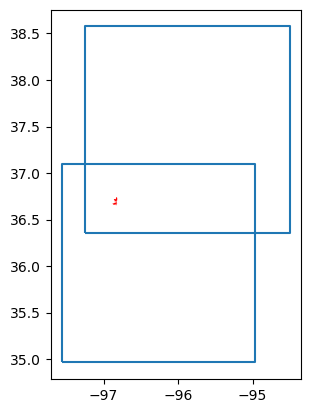

In [148]:
fig, ax = plt.subplots()
#conus_landsat[conus_landsat.SCENE_ID.isin(imgs)].boundary.plot(ax=ax)
test_db[test_db.fire_id == 'OK3669309683920150330'].boundary.plot(ax=ax)
mtbs[mtbs.Event_ID == "OK3669309683920150330"].plot(ax=ax, color='red')

In [42]:
conus_landsat[
    (conus_landsat.geometry.contains(mtbs[mtbs.Incid_Name == "AUGUST COMPLEX"].iloc[0].geometry))
    & (conus_landsat.DATE_ACQUIRED.isin(time_range))
]

,SCENE_ID,PRODUCT_ID,SPACECRAFT_ID,SENSOR_ID,DATE_ACQUIRED,COLLECTION_NUMBER,COLLECTION_CATEGORY,SENSING_TIME,DATA_TYPE,WRS_PATH,WRS_ROW,CLOUD_COVER,NORTH_LAT,SOUTH_LAT,WEST_LON,EAST_LON,TOTAL_SIZE,BASE_URL,geometry
2682004,LE70450322020221EDC00,LE07_L1TP_045032_20200808_20200903_01_T1,LANDSAT_7,ETM,2020-08-08,1,T1,2020-08-08T18:19:48.2102829Z,L1TP,45,32,0.00,41.31560,39.37312,-124.37156,-121.4254,251719676,gs://gcp-public-data-landsat/LE07/01/045/032/L...,"POLYGON ((-124.37156 39.37312, -124.37156 41.3..."
7944299,LC80450322020213LGN00,LC08_L1TP_045032_20200731_20200807_01_T1,LANDSAT_8,OLI_TIRS,2020-07-31,1,T1,2020-07-31T18:51:24.5566260Z,L1TP,45,32,1.98,41.38572,39.25613,-124.13623,-121.3628,1070770782,gs://gcp-public-data-landsat/LC08/01/045/032/L...,"POLYGON ((-124.13623 39.25613, -124.13623 41.3..."
